<a href="https://colab.research.google.com/github/s31302/suml_projekt/blob/main/suml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

local_paths = [Path("data/airbnb_train.csv"), Path("airbnb_train.csv")]
data_path = next((path for path in local_paths if path.is_file()), None)

if data_path is None and Path("/content").is_dir():
    from google.colab import drive

    drive.mount("/content/drive")
    data_path = Path("/content/drive/MyDrive/data/airbnb_train.csv")

if data_path is None or not data_path.is_file():
    raise FileNotFoundError("Umieść airbnb_train.csv w katalogu data/ obok notebooka.")

housing = pd.read_csv(data_path)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

### 1. Kontrola jakości danych

In [2]:
price = housing["price"]
valid_price = np.isfinite(price) & price.gt(0)

display(pd.Series({
    "Liczba ofert": len(housing),
    "Liczba kolumn": housing.shape[1],
    "Liczba miast": housing["city"].nunique(),
    "Powtórzone identyfikatory ofert": housing["id"].duplicated().sum(),
    "Brakujące identyfikatory ofert": housing["id"].isna().sum(),
    "Brakujące lub niepoprawne ceny dla MAPE": (~valid_price).sum(),
}))
display(price.describe(percentiles=[0.01, 0.1, 0.5, 0.9, 0.99]))
display(housing.isna().mean().mul(100).nlargest(15).rename("Braki (%)").round(2))

if not valid_price.all():
    raise ValueError("MAPE wymaga skończonych, dodatnich cen we wszystkich wierszach.")

occupancy = housing["estimated_occupancy_l365d"]
implied_price = housing["estimated_revenue_l365d"] / occupancy.where(occupancy.gt(0))
comparable = implied_price.notna()
matches = implied_price.sub(price).abs().lt(1) & comparable
print(f"Ceny odtworzone z przychodu i obłożenia (różnica < 1): "
      f"{matches.sum():,} z {comparable.sum():,} dostępnych przypadków.")

Ceny odtworzone z przychodu i obłożenia (różnica < 1): 70,184 z 70,184 dostępnych przypadków.


Liczba ofert                               208856
Liczba kolumn                                  52
Liczba miast                                  108
Powtórzone identyfikatory ofert                 0
Brakujące identyfikatory ofert                  0
Brakujące lub niepoprawne ceny dla MAPE         0
dtype: int64

count    208856.000000
mean        207.115836
std         197.238695
min           1.000000
1%           29.000000
10%          55.000000
50%         136.000000
90%         472.000000
99%         950.000000
max        1000.000000
Name: price, dtype: float64

host_neighbourhood             60.68
availability_eoy               53.37
number_of_reviews_ly           53.37
estimated_occupancy_l365d      53.37
estimated_revenue_l365d        53.37
neighborhood_overview          51.25
host_about                     48.20
host_location                  25.51
review_scores_checkin          19.47
review_scores_value            19.47
review_scores_location         19.47
review_scores_communication    19.47
review_scores_accuracy         19.46
review_scores_cleanliness      19.46
review_scores_rating           19.46
Name: Braki (%), dtype: float64

Ceny pozostają w jednostkach zapisanych w CSV. Wykresy cen ograniczono dla czytelności do wartości poniżej 95. percentyla. Trening i ocena obejmują cały zakres cen.

### 2. Rozkład cen

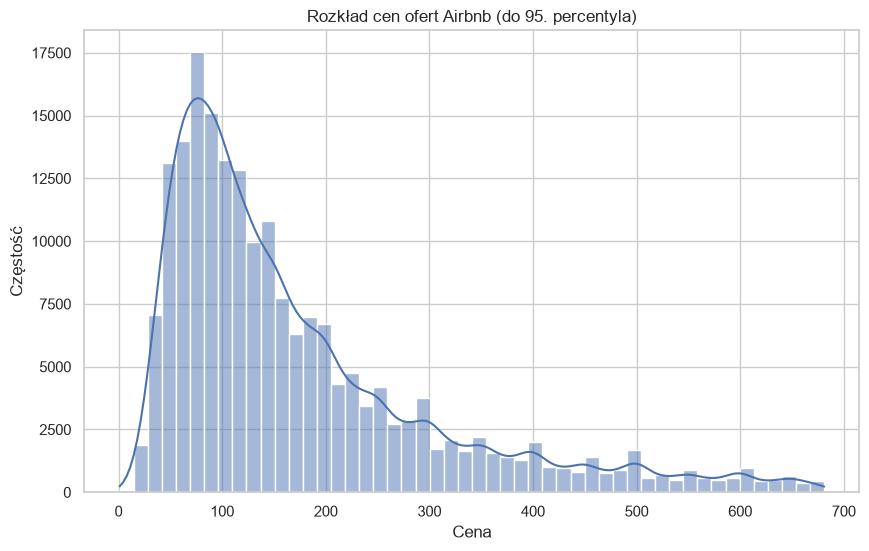

In [3]:
q_limit = housing['price'].quantile(0.95)
sns.histplot(housing[housing['price'] < q_limit]['price'], bins=50, kde=True)
plt.title('Rozkład cen ofert Airbnb (do 95. percentyla)')
plt.xlabel('Cena')
plt.ylabel('Częstość')
plt.show()

### 3. Typ pokoju a cena

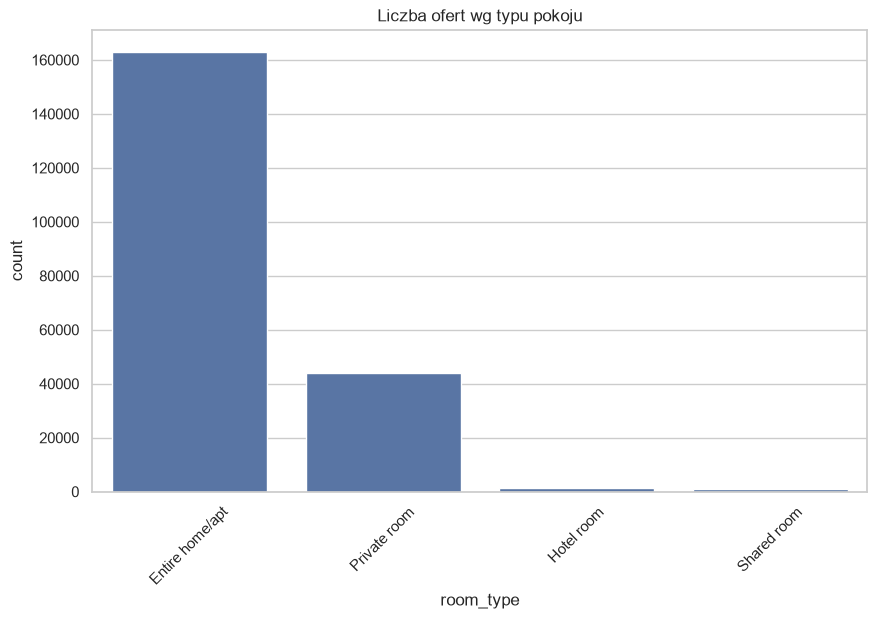

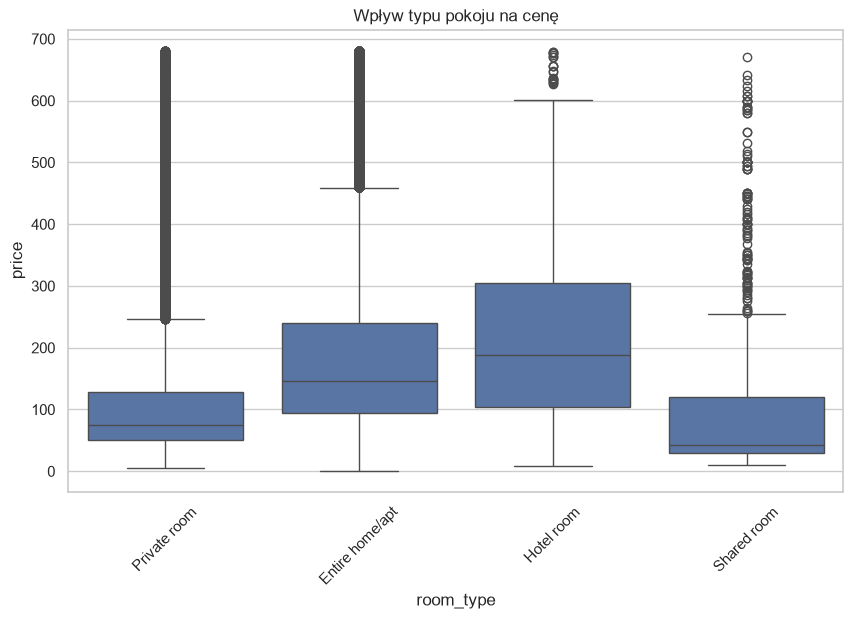

In [4]:
# Liczba ofert w zależności od typu pokoju
sns.countplot(data=housing, x='room_type', order=housing['room_type'].value_counts().index)
plt.title('Liczba ofert wg typu pokoju')
plt.xticks(rotation=45)
plt.show()

sns.boxplot(data=housing[housing['price'] < q_limit], x='room_type', y='price')
plt.title('Wpływ typu pokoju na cenę')
plt.xticks(rotation=45)
plt.show()

### 4. Miasto a cena

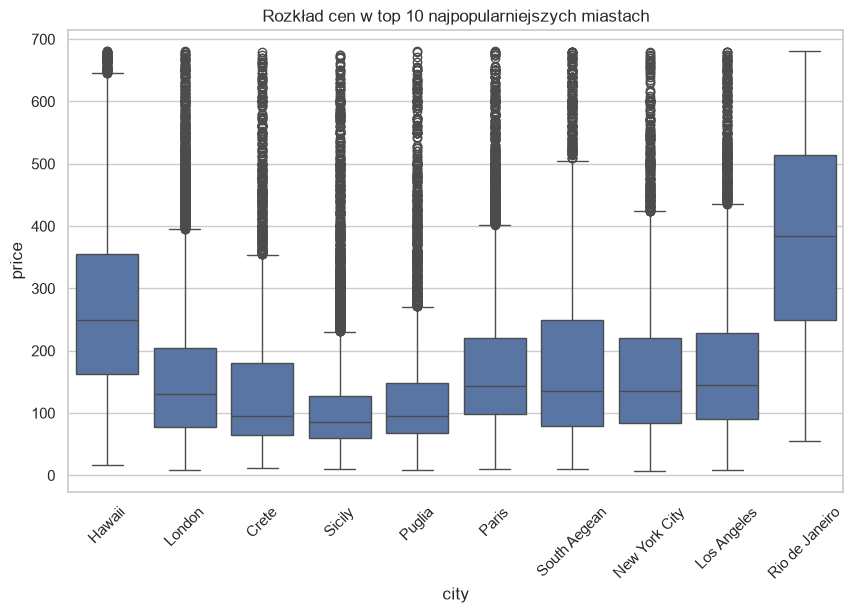

In [5]:
# Top 10 najpopularniejszych miast w zbiorze danych
top_cities = housing['city'].value_counts().head(10).index
housing_top_cities = housing[housing['city'].isin(top_cities)]

sns.boxplot(data=housing_top_cities[housing_top_cities['price'] < q_limit], x='city', y='price')
plt.title('Rozkład cen w top 10 najpopularniejszych miastach')
plt.xticks(rotation=45)
plt.show()

### 5. Cechy i korelacje

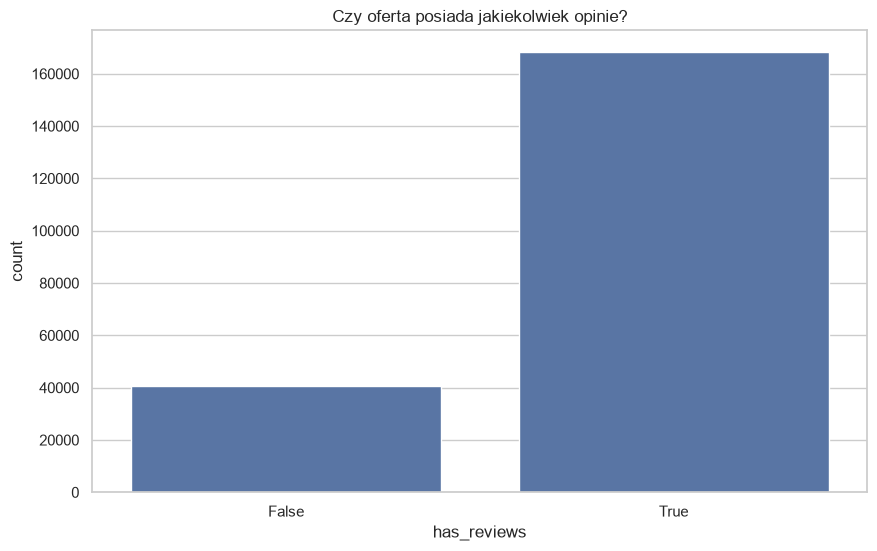

In [6]:
# Tworzenie nowych cech: pojemność na sypialnię oraz informacja czy obiekt ma jakiekolwiek oceny
housing['beds_per_bedroom'] = housing['beds'] / (housing['bedrooms'] + 0.1)
housing['has_reviews'] = housing['number_of_reviews'] > 0

sns.countplot(data=housing, x='has_reviews')
plt.title('Czy oferta posiada jakiekolwiek opinie?')
plt.show()

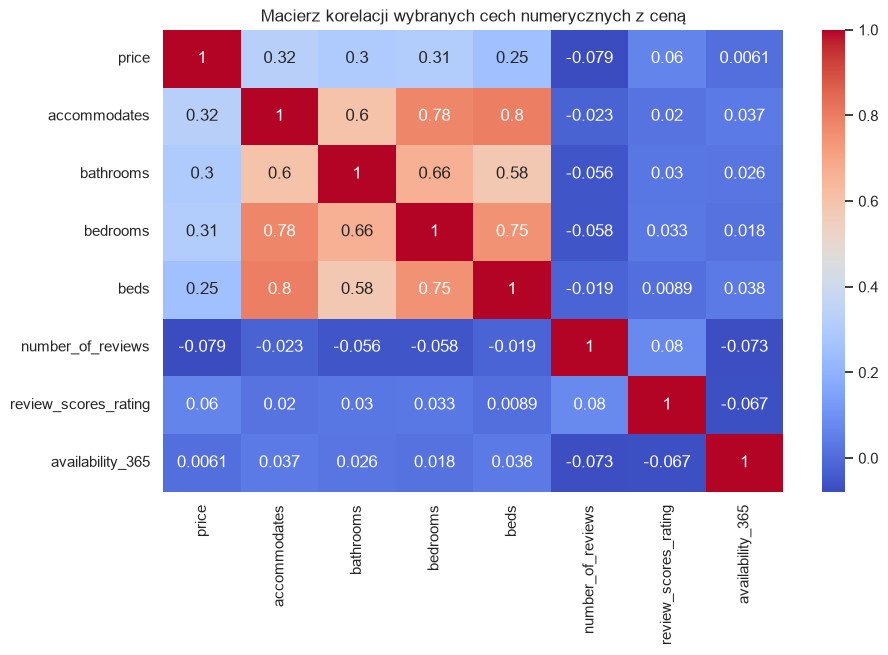

In [7]:
# Wybór kluczowych kolumn numerycznych do analizy korelacji
numerical_cols = ['price', 'accommodates', 'bathrooms', 'bedrooms', 'beds',
                  'number_of_reviews', 'review_scores_rating', 'availability_365']

correlation = housing[numerical_cols].corr(numeric_only=True)
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt=".2g")
plt.title('Macierz korelacji wybranych cech numerycznych z ceną')
plt.show()


### 6. Cechy i podział danych

Losowy podział 80/20 z ziarnem 42 zachowuje zbiór testowy z wcześniejszego notebooka. Ocenia przewidywanie cen dla innych ofert z tego samego zbioru. Każdy model dostaje te same wiersze. Imputację i słowniki kategorii dopasowujemy na zbiorze treningowym.

Regresja liniowa i Random Forest używają zestawu cech z poprzedniego notebooka. XGBoost uwzględnia dodatkowo typ obiektu, informacje o gospodarzu, szczegółowe oceny oraz wybrane udogodnienia. Pominięto identyfikatory oraz szacowany przychód i obłożenie. Iloraz tych dwóch ostatnich kolumn odtwarza cenę.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

seed = 42
baseline_categories = [
    "room_type", "city", "host_is_superhost", "host_identity_verified", "has_availability",
]
baseline_numeric = [
    "accommodates", "bathrooms", "bedrooms", "beds", "latitude", "longitude",
    "availability_30", "availability_60", "availability_90", "availability_365",
    "number_of_reviews", "number_of_reviews_ltm", "number_of_reviews_l30d",
    "review_scores_rating", "reviews_per_month",
]
extra_categories = ["property_type", "host_response_time", "host_neighbourhood"]
extra_numeric = [
    "host_listings_count", "host_total_listings_count", "beds_per_bedroom", "has_reviews",
    "review_scores_accuracy", "review_scores_cleanliness", "review_scores_checkin",
    "review_scores_communication", "review_scores_location", "review_scores_value",
]
amenities = [
    "Wifi", "Kitchen", "Air conditioning", "Heating", "Washer", "Dryer", "Pool",
    "Hot tub", "Free parking", "Private entrance", "Self check-in", "Elevator",
    "Dedicated workspace", "Patio or balcony", "Microwave", "Dishwasher",
]

categorical_cols = baseline_categories + extra_categories
feature_cols = baseline_categories + baseline_numeric + extra_categories + extra_numeric
features = housing[feature_cols].copy()
features["has_reviews"] = features["has_reviews"].astype("int8")
features["bathrooms"] = pd.to_numeric(features["bathrooms"], errors="coerce")
for col in ["host_response_rate", "host_acceptance_rate"]:
    features[col] = pd.to_numeric(housing[col].str.rstrip("%"), errors="coerce") / 100

for col in ["host_since", "first_review", "last_review"]:
    features[f"{col}_year"] = pd.to_datetime(housing[col], errors="coerce").dt.year

amenity_text = housing["amenities"]
features["amenity_count"] = amenity_text.str.count(r'",\s*"').add(1).where(amenity_text.ne("[]"), 0)
for amenity in amenities:
    features[f"amenity_{amenity}"] = amenity_text.str.contains(
        amenity, case=False, regex=False, na=False
    ).astype("int8")

X_train, X_test, y_train, y_test = train_test_split(
    features, price, test_size=0.2, random_state=seed
)
print(f"Trening: {len(y_train):,} ofert. Test: {len(y_test):,} ofert.")

baseline_preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), baseline_numeric),
    ("categorical", make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32),
    ), baseline_categories),
])
baseline_train = baseline_preprocessor.fit_transform(X_train).astype(np.float32)
baseline_test = baseline_preprocessor.transform(X_test).astype(np.float32)

xgb_train = X_train.astype({col: "category" for col in categorical_cols})
xgb_test = X_test.copy()
for col in categorical_cols:
    # Kategorie niewidziane w treningu stają się brakami danych.
    categories = xgb_train[col].cat.categories
    known_values = X_test[col].where(X_test[col].isin(categories))
    xgb_test[col] = pd.Categorical(known_values, categories=categories)

Trening: 167,084 ofert. Test: 41,772 ofert.


### 7. Trening modeli

Punktem odniesienia jest mediana cen z treningu. Regresja liniowa i Random Forest uczą się na cenach. Pierwszy wariant XGBoost uczy się na logarytmie ceny i odwraca transformację po predykcji. Drugi używa błędu bezwzględnego ważonego odwrotnością ceny. Limit wagi dla cen poniżej 15 ogranicza wpływ pojedynczych bardzo tanich ofert na trening. Testowe MAPE liczymy standardowo, z rzeczywistą ceną w mianowniku.

In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

predictions = {"Model bazowy (mediana)": np.full(len(y_test), y_train.median())}
baseline_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=50, max_depth=12, random_state=seed, n_jobs=4
    ),
}
for name, model in baseline_models.items():
    print(f"Trening: {name}", flush=True)
    model.fit(baseline_train, y_train)
    predictions[name] = model.predict(baseline_test)

xgb_params = dict(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    min_child_weight=5,
    subsample=0.9,
    colsample_bytree=0.9,
    tree_method="hist",
    enable_categorical=True,
    random_state=seed,
    n_jobs=4,
)

print("Trening: XGBoost (log ceny)", flush=True)
xgb_log_model = XGBRegressor(objective="reg:squarederror", **xgb_params)
xgb_log_model.fit(xgb_train, np.log(y_train))
predictions["XGBoost (log ceny)"] = np.exp(xgb_log_model.predict(xgb_test))

print("Trening: XGBoost (ważony MAE)", flush=True)
xgb_weighted_model = XGBRegressor(objective="reg:absoluteerror", **xgb_params)
weights = 1 / y_train.clip(lower=15)
xgb_weighted_model.fit(xgb_train, y_train, sample_weight=weights / weights.mean())
predictions["XGBoost (ważony MAE)"] = xgb_weighted_model.predict(xgb_test)

Trening: Linear Regression
Trening: Random Forest
Trening: XGBoost (log ceny)
Trening: XGBoost (ważony MAE)


### 8. Porównanie na zbiorze testowym

In [10]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

results = pd.DataFrame([
    {
        "Model": name,
        "MAPE (%)": 100 * mean_absolute_percentage_error(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "R²": r2_score(y_test, pred),
    }
    for name, pred in predictions.items()
]).sort_values("MAPE (%)", ignore_index=True)

display(results.round(2))

best = results.iloc[0]
print(f"Najniższe testowe MAPE: {best['MAPE (%)']:.2f}% ({best['Model']}).")

Najniższe testowe MAPE: 29.93% (XGBoost (ważony MAE)).


,Model,MAPE (%),MAE,R²
0,XGBoost (ważony MAE),29.93,68.99,0.58
1,XGBoost (log ceny),30.71,58.92,0.72
2,Random Forest,51.12,74.85,0.64
3,Linear Regression,56.18,83.08,0.58
4,Model bazowy (mediana),70.36,124.91,-0.13
